In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import fitsio

In [3]:
def load_power_spectrum(file):
    
    table = pd.read_csv(file,
    sep=r"\s+",
    comment="#",
    names=["k (h/Mpc)", "P_k (Mpc/h)^3", "P_linear_k (Mpc/h)^3"])

    k = table["k (h/Mpc)"]
    Pk = table["P_k (Mpc/h)^3"]
    
    return k, Pk

def plot_power_spectrum(k, Pk):

    fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=300)

    ax.loglog(k, Pk, lw=2)

    ax.set_xlabel(r"$k \; [h/\mathrm{Mpc}]$", fontsize=14)
    ax.set_ylabel(r"$P(k)[(\mathrm{Mpc}/h)^3]$", fontsize=14)

    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.tick_params(axis='both', which='minor', labelsize=10)

    plt.tight_layout()
    plt.savefig("fig/power_spectrum.png")
    plt.show()

def compare_power_spectrum(ks, Pks, labels, title=None):

    fig, ax = plt.subplots(figsize=(6.5, 5.5), dpi=300)

    for i in range(len(ks)):
        ax.loglog(ks[i], Pks[i], lw=2, label=labels[i])
    
    if title:
        ax.set_title(title, fontsize=14)

    ax.set_xlabel(r"$k \; [h/\mathrm{Mpc}]$", fontsize=14)
    ax.set_ylabel(r"$P(k)[(\mathrm{Mpc}/h)^3]$", fontsize=14)

    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.tick_params(axis='both', which='minor', labelsize=10)

    plt.tight_layout()
    plt.legend()
    plt.savefig("fig/power_spectrum.png")
    plt.show()

def ratio_power_spectrum(k1, Pk1, k2, Pk2, labels):

    fig, ax = plt.subplots(figsize=(8.5, 5.5), dpi=300)

    ax.plot(k1, Pk2/Pk1, lw=2)

    ax.set_xlabel(r"$k \; [h/\mathrm{Mpc}]$", fontsize=14)
    ax.set_ylabel(r"$p^{\mathrm{" + labels[1] + r"}}(k,z=0)/p^{\mathrm{" + labels[0] + r"}}(k,z=0)$", fontsize=14)
    ax.set_xscale('log')
    #ax.set_xlim(2e-1,2)

    ax.tick_params(axis='both', which='major', labelsize=12)
    ax.tick_params(axis='both', which='minor', labelsize=10)

    plt.tight_layout()
    plt.savefig("fig/ratio_power_spectrum.png")
    plt.show()

# Load power spectra

In [4]:
redshift = 1.000
redshift_label = f'{redshift:.3f}'

# Average Bart's comparison over all Box1 ... Box10 realizations
n_boxes = 10
k_LCDM_Bart_boxes = []
Pk_LCDM_Bart_boxes = []
k_nDGP_Bart_boxes = []
Pk_nDGP_Bart_boxes = []

for box_n in range(1, n_boxes + 1):
    k_l, Pk_l = load_power_spectrum(f'/home/biel/Hi-COLA/Comparison/Box{box_n}/Bart_LCDM_snap_3.txt')
    k_n, Pk_n = load_power_spectrum(f'/home/biel/Hi-COLA/Comparison/Box{box_n}/Bart_nDGP_snap_3.txt')
    k_LCDM_Bart_boxes.append(np.asarray(k_l))
    Pk_LCDM_Bart_boxes.append(np.asarray(Pk_l))
    k_nDGP_Bart_boxes.append(np.asarray(k_n))
    Pk_nDGP_Bart_boxes.append(np.asarray(Pk_n))

k_LCDM_Bart = k_LCDM_Bart_boxes[0]
k_nDGP_Bart = k_nDGP_Bart_boxes[0]
Pk_LCDM_Bart_stack = np.vstack(Pk_LCDM_Bart_boxes)
Pk_nDGP_Bart_stack = np.vstack(Pk_nDGP_Bart_boxes)
Pk_LCDM_Bart = Pk_LCDM_Bart_stack.mean(axis=0)
Pk_LCDM_Bart_std = Pk_LCDM_Bart_stack.std(axis=0)
Pk_nDGP_Bart = Pk_nDGP_Bart_stack.mean(axis=0)
Pk_nDGP_Bart_std = Pk_nDGP_Bart_stack.std(axis=0)

Pk_nDGP_over_LCDM_Bart_stack = np.vstack([
    np.interp(k_LCDM_Bart, k_nDGP_Bart_boxes[i], Pk_nDGP_Bart_boxes[i]) / Pk_LCDM_Bart_boxes[i]
    for i in range(n_boxes)
])
Pk_nDGP_over_LCDM_Bart = Pk_nDGP_over_LCDM_Bart_stack.mean(axis=0)
Pk_nDGP_over_LCDM_Bart_std = Pk_nDGP_over_LCDM_Bart_stack.std(axis=0)

# Load our simulation results at z=1.650
k_LCDM_Me, Pk_LCDM_Me = load_power_spectrum(f'/scratch/biel/LCDM_Bart/snapshot_LCDM_Bart_z{redshift_label}/pofk_z{redshift_label}.txt')
k_nDGP_Me, Pk_nDGP_Me = load_power_spectrum(f'/scratch/biel/nDGP_Bart/snapshot_nDGP_Bart_z{redshift_label}/pofk_z{redshift_label}.txt')


# Plot 1

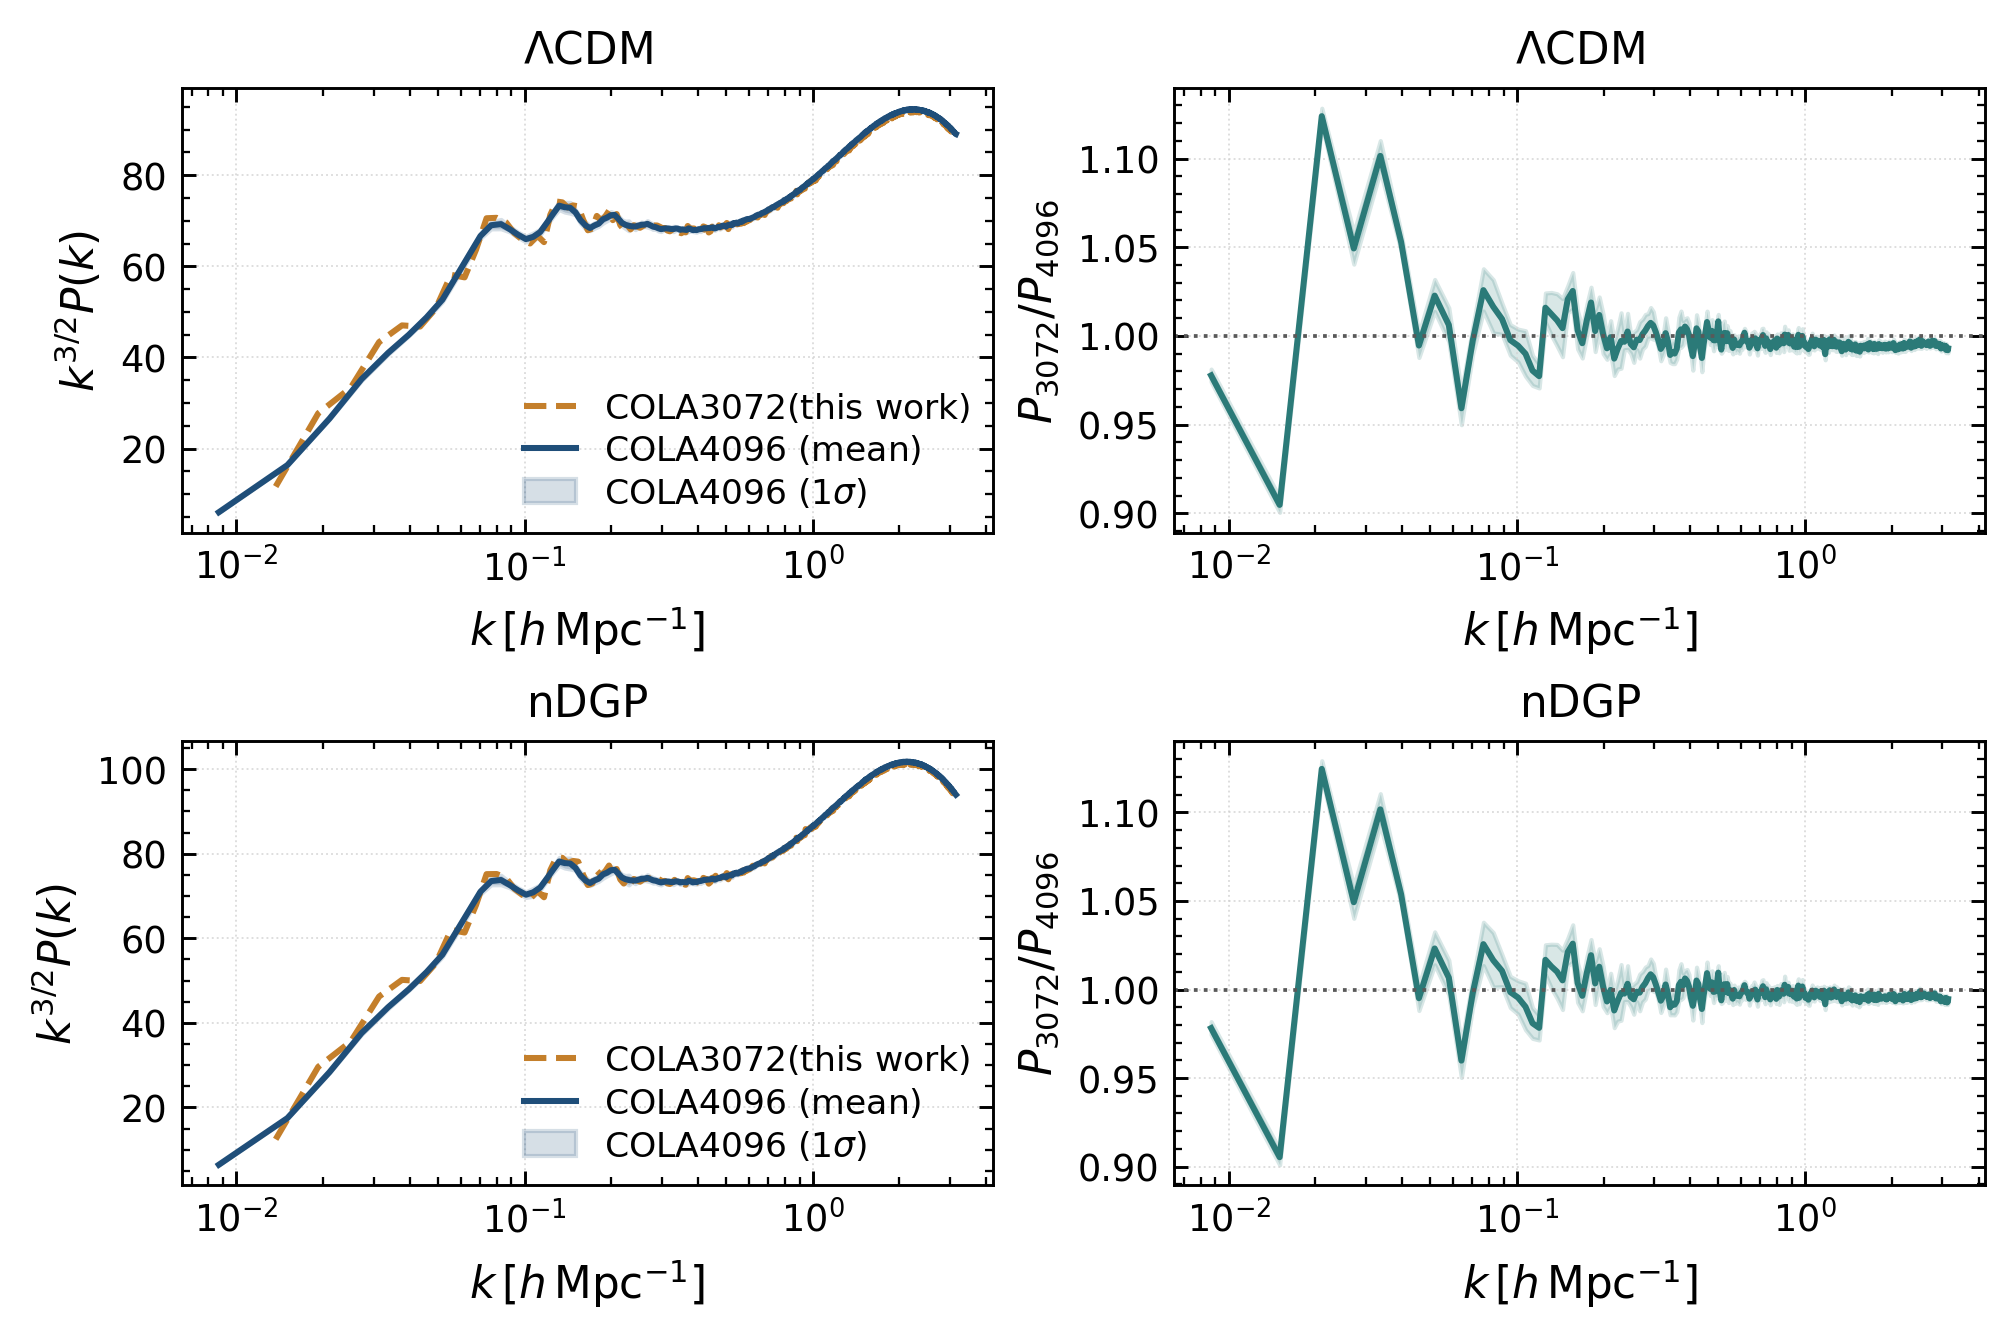

In [5]:
# Four-panel comparison at z=1.650: LCDM (top row) vs nDGP (bottom row)
k_LCDM_Bart_plot = np.asarray(k_LCDM_Bart)
Pk_LCDM_Bart_plot = np.asarray(Pk_LCDM_Bart)
Pk_LCDM_Bart_std_plot = np.asarray(Pk_LCDM_Bart_std)
k_nDGP_Bart_plot = np.asarray(k_nDGP_Bart)
Pk_nDGP_Bart_plot = np.asarray(Pk_nDGP_Bart)
Pk_nDGP_Bart_std_plot = np.asarray(Pk_nDGP_Bart_std)
bart_label = r'$\mathrm{COLA4096\ (mean)}$'

k_LCDM_Me_plot = np.asarray(k_LCDM_Me)
Pk_LCDM_Me_plot = np.asarray(Pk_LCDM_Me)
k_nDGP_Me_plot = np.asarray(k_nDGP_Me)
Pk_nDGP_Me_plot = np.asarray(Pk_nDGP_Me)

# Cut our power spectra to the comparison's k range
mask_LCDM_Me = (k_LCDM_Me_plot >= k_LCDM_Bart_plot.min()) & (k_LCDM_Me_plot <= k_LCDM_Bart_plot.max())
k_LCDM_Me_plot = k_LCDM_Me_plot[mask_LCDM_Me]
Pk_LCDM_Me_plot = Pk_LCDM_Me_plot[mask_LCDM_Me]
mask_nDGP_Me = (k_nDGP_Me_plot >= k_nDGP_Bart_plot.min()) & (k_nDGP_Me_plot <= k_nDGP_Bart_plot.max())
k_nDGP_Me_plot = k_nDGP_Me_plot[mask_nDGP_Me]
Pk_nDGP_Me_plot = Pk_nDGP_Me_plot[mask_nDGP_Me]

Pk_LCDM_Me_on_Bart = np.interp(k_LCDM_Bart_plot, k_LCDM_Me_plot, Pk_LCDM_Me_plot)
Pk_nDGP_Me_on_Bart = np.interp(k_nDGP_Bart_plot, k_nDGP_Me_plot, Pk_nDGP_Me_plot)

Pk_LCDM_Bart_low = np.maximum(Pk_LCDM_Bart_plot - Pk_LCDM_Bart_std_plot, 1e-30)
Pk_LCDM_Bart_high = Pk_LCDM_Bart_plot + Pk_LCDM_Bart_std_plot
Pk_LCDM_COLA_over_Bart = Pk_LCDM_Me_on_Bart / Pk_LCDM_Bart_plot
Pk_LCDM_COLA_over_Bart_low = Pk_LCDM_Me_on_Bart / Pk_LCDM_Bart_high
Pk_LCDM_COLA_over_Bart_high = Pk_LCDM_Me_on_Bart / Pk_LCDM_Bart_low

Pk_nDGP_Bart_low = np.maximum(Pk_nDGP_Bart_plot - Pk_nDGP_Bart_std_plot, 1e-30)
Pk_nDGP_Bart_high = Pk_nDGP_Bart_plot + Pk_nDGP_Bart_std_plot
Pk_nDGP_COLA_over_Bart = Pk_nDGP_Me_on_Bart / Pk_nDGP_Bart_plot
Pk_nDGP_COLA_over_Bart_low = Pk_nDGP_Me_on_Bart / Pk_nDGP_Bart_high
Pk_nDGP_COLA_over_Bart_high = Pk_nDGP_Me_on_Bart / Pk_nDGP_Bart_low

fig_size = (6.6, 4.35)
label_size = 10.5
tick_size = 8.8
legend_size = 8.3
line_width = 1.45
std_alpha = 0.18
cola_color = '#c47f2b'
bart_color = '#1f4e79'
ratio_color = '#2b7a78'
band_color = bart_color
ref_color = '0.35'

fig, axes = plt.subplots(2, 2, figsize=fig_size, dpi=300, constrained_layout=True)
ax_tl, ax_tr = axes[0]
ax_bl, ax_br = axes[1]

# Top row: LCDM
ax_tl.semilogx(k_LCDM_Me_plot, k_LCDM_Me_plot**(3/2) * Pk_LCDM_Me_plot, lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA3072 (this\ work)}$')
ax_tl.semilogx(k_LCDM_Bart_plot, k_LCDM_Bart_plot**(3/2) * Pk_LCDM_Bart_plot, lw=line_width, color=bart_color, label=bart_label)
ax_tl.fill_between(
    k_LCDM_Bart_plot,
    k_LCDM_Bart_plot**(3/2) * Pk_LCDM_Bart_low,
    k_LCDM_Bart_plot**(3/2) * Pk_LCDM_Bart_high,
    color=band_color,
    alpha=std_alpha,
    label=r'$\mathrm{COLA4096}\ (1\sigma)$',
)
ax_tl.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_tl.set_ylabel(r'$k^{3/2} P(k)$', fontsize=label_size)
ax_tl.set_title(r'$\Lambda\mathrm{CDM}$', fontsize=label_size)
ax_tl.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)

ax_tr.semilogx(k_LCDM_Bart_plot, Pk_LCDM_COLA_over_Bart, lw=line_width, color=ratio_color)
ax_tr.fill_between(k_LCDM_Bart_plot, Pk_LCDM_COLA_over_Bart_low, Pk_LCDM_COLA_over_Bart_high, color=ratio_color, alpha=std_alpha)
ax_tr.axhline(1.0, color=ref_color, lw=0.9, ls=':')
ax_tr.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_tr.set_ylabel(r'$P_{\mathrm{3072}} / P_{\mathrm{4096}}$', fontsize=label_size)
ax_tr.set_title(r'$\Lambda\mathrm{CDM}$', fontsize=label_size)

# Bottom row: nDGP
ax_bl.semilogx(k_nDGP_Me_plot, k_nDGP_Me_plot**(3/2) * Pk_nDGP_Me_plot, lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA3072 (this\ work)}$')
ax_bl.semilogx(k_nDGP_Bart_plot, k_nDGP_Bart_plot**(3/2) * Pk_nDGP_Bart_plot, lw=line_width, color=bart_color, label=bart_label)
ax_bl.fill_between(
    k_nDGP_Bart_plot,
    k_nDGP_Bart_plot**(3/2) * Pk_nDGP_Bart_low,
    k_nDGP_Bart_plot**(3/2) * Pk_nDGP_Bart_high,
    color=band_color,
    alpha=std_alpha,
    label=r'$\mathrm{COLA4096}\ (1\sigma)$',
)
ax_bl.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_bl.set_ylabel(r'$k^{3/2} P(k)$', fontsize=label_size)
ax_bl.set_title(r'$\mathrm{nDGP}$', fontsize=label_size)
ax_bl.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)

ax_br.semilogx(k_nDGP_Bart_plot, Pk_nDGP_COLA_over_Bart, lw=line_width, color=ratio_color)
ax_br.fill_between(k_nDGP_Bart_plot, Pk_nDGP_COLA_over_Bart_low, Pk_nDGP_COLA_over_Bart_high, color=ratio_color, alpha=std_alpha)
ax_br.axhline(1.0, color=ref_color, lw=0.9, ls=':')
ax_br.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax_br.set_ylabel(r'$P_{\mathrm{3072}} / P_{\mathrm{4096}}$', fontsize=label_size)
ax_br.set_title(r'$\mathrm{nDGP}$', fontsize=label_size)

for ax in (ax_tl, ax_tr, ax_bl, ax_br):
    ax.minorticks_on()
    ax.grid(True, which='major', ls=':', color='0.82', alpha=0.75, lw=0.45)
    ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, labelsize=tick_size, length=3.4, width=0.7)
    ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, labelsize=tick_size - 0.8, length=2.0, width=0.55)
    for spine in ax.spines.values():
        spine.set_linewidth(0.7)

plt.show()


# Plot 1b

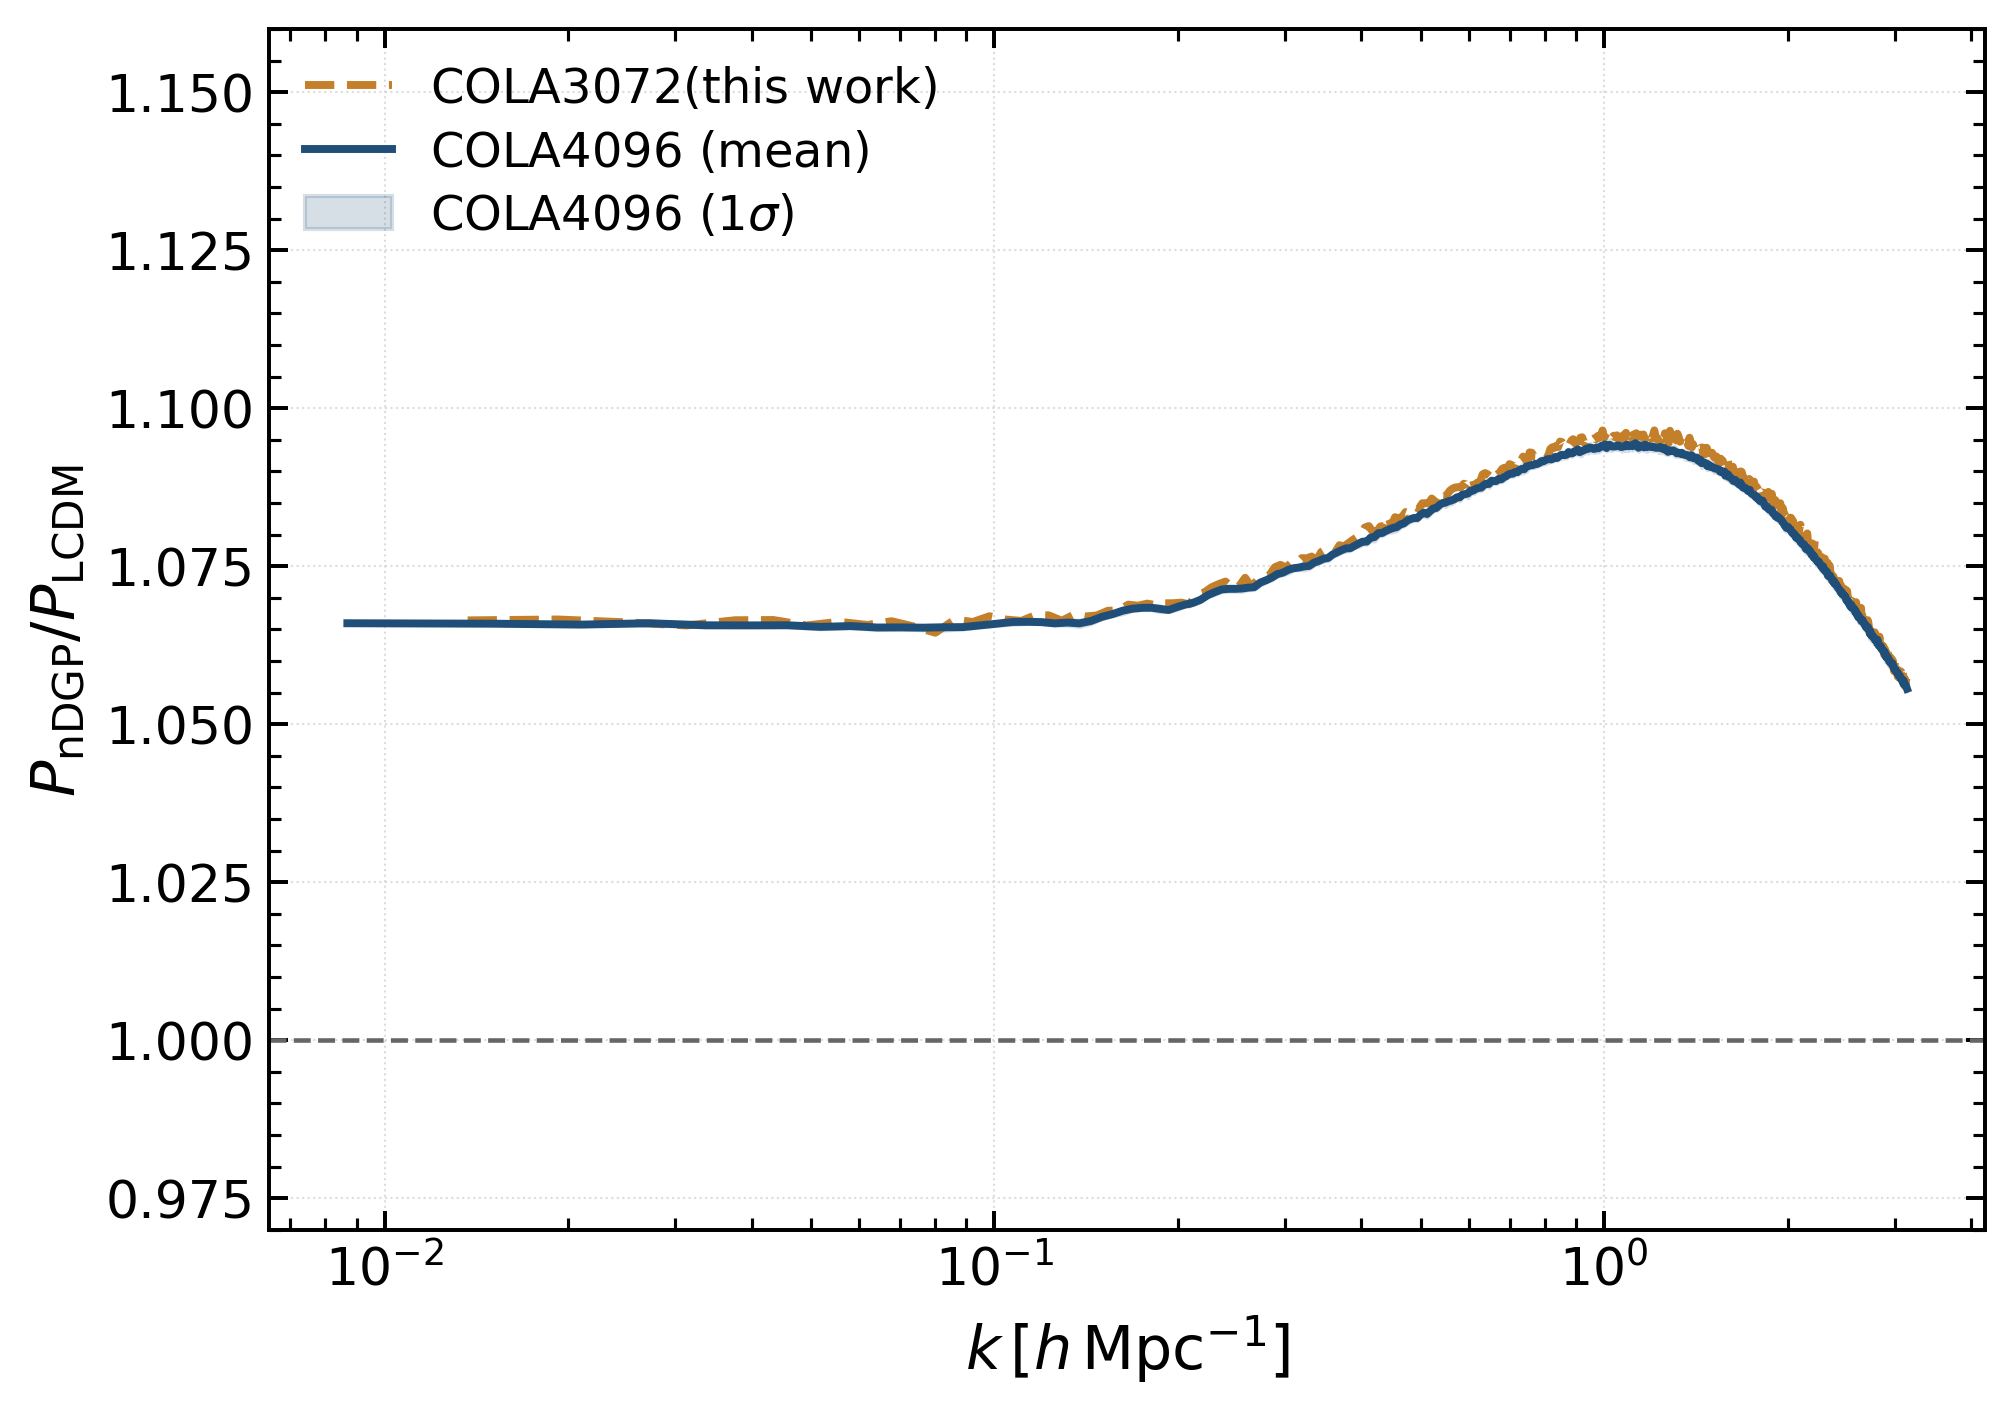

In [13]:
# nDGP / LCDM power spectrum ratio at z=1.650
k_LCDM_Bart_plot = np.asarray(k_LCDM_Bart)
k_nDGP_Bart_plot = np.asarray(k_nDGP_Bart)
k_LCDM_Me_plot = np.asarray(k_LCDM_Me)
Pk_LCDM_Me_plot = np.asarray(Pk_LCDM_Me)
k_nDGP_Me_plot = np.asarray(k_nDGP_Me)
Pk_nDGP_Me_plot = np.asarray(Pk_nDGP_Me)
bart_label = r'$\mathrm{COLA4096\ (mean)}$'

# Cut our power spectra to the comparison's k range
mask_LCDM_Me = (k_LCDM_Me_plot >= k_LCDM_Bart_plot.min()) & (k_LCDM_Me_plot <= k_LCDM_Bart_plot.max())
k_LCDM_Me_plot = k_LCDM_Me_plot[mask_LCDM_Me]
Pk_LCDM_Me_plot = Pk_LCDM_Me_plot[mask_LCDM_Me]
mask_nDGP_Me = (k_nDGP_Me_plot >= k_nDGP_Bart_plot.min()) & (k_nDGP_Me_plot <= k_nDGP_Bart_plot.max())
k_nDGP_Me_plot = k_nDGP_Me_plot[mask_nDGP_Me]
Pk_nDGP_Me_plot = Pk_nDGP_Me_plot[mask_nDGP_Me]

Pk_nDGP_Me_on_LCDM = np.interp(k_LCDM_Me_plot, k_nDGP_Me_plot, Pk_nDGP_Me_plot)

# This is a standalone, one-column figure (unlike the four-panel plot above), so it will be
# shrunk more to fit a document column -- sizes here are scaled up accordingly to stay readable.
fig_size = (6.6, 4.6)
label_size = 14.5
tick_size = 12.5
legend_size = 11.5
line_width = 1.9
std_alpha = 0.18
cola_color = '#c47f2b'
bart_color = '#1f4e79'
band_color = bart_color

fig, ax = plt.subplots(figsize=fig_size, dpi=300, constrained_layout=True)

ax.semilogx(k_LCDM_Me_plot, Pk_nDGP_Me_on_LCDM / Pk_LCDM_Me_plot, lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA3072 (this\ work)}$')
ax.semilogx(k_LCDM_Bart_plot, Pk_nDGP_over_LCDM_Bart, lw=line_width, color=bart_color, label=bart_label)
ax.fill_between(
    k_LCDM_Bart_plot,
    Pk_nDGP_over_LCDM_Bart - Pk_nDGP_over_LCDM_Bart_std,
    Pk_nDGP_over_LCDM_Bart + Pk_nDGP_over_LCDM_Bart_std,
    color=band_color,
    alpha=std_alpha,
    label=r'$\mathrm{COLA4096}\ (1\sigma)$',
)
ax.set_xlabel(r'$k\,[h\,\mathrm{Mpc}^{-1}]$', fontsize=label_size)
ax.set_ylabel(r'$P_{\mathrm{nDGP}} / P_{\mathrm{LCDM}}$', fontsize=label_size)
ax.legend(fontsize=legend_size, frameon=False, handlelength=1.8, borderaxespad=0.35, labelspacing=0.35, loc='upper left')
ax.axhline(1.0, color='0.4', lw=1.1, ls='--')
ax.set_ylim(0.97, 1.16)

ax.minorticks_on()
ax.grid(True, which='major', ls=':', color='0.82', alpha=0.75, lw=0.5)
ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, labelsize=tick_size, length=4.6, width=0.95)
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, labelsize=tick_size - 1.2, length=2.8, width=0.75)
for spine in ax.spines.values():
    spine.set_linewidth(0.95)

plt.show()

# Load halo catalogs

In [7]:
from pathlib import Path

boxsize = 1024.0
snapshot_index_by_redshift = {
    1.650: 0,
    1.400: 1,
    1.200: 2,
    1.000: 3,
}
snapshot_index = snapshot_index_by_redshift[round(redshift, 3)]


def load_hmf_table(file):
    table = np.loadtxt(file, comments='#')
    return table[:, 0], table[:, 1]


def load_pipeline_hmf(file, target_mass_grid):
    file = Path(file)
    if not file.exists():
        raise FileNotFoundError(
            f'Missing {file}. Run /home/biel/Hi-COLA/halo_finder512.sh for this simulation first.'
        )
    mass, hmf = load_hmf_table(file)
    return np.interp(target_mass_grid, mass, hmf, left=np.nan, right=np.nan)

# Average Bart's cumulative HMF over the same boxes used above.
M_LCDM_Bart_boxes = []
hmf_LCDM_Bart_boxes = []
M_nDGP_Bart_boxes = []
hmf_nDGP_Bart_boxes = []

for box_n in range(1, n_boxes + 1):
    M_l, hmf_l = load_hmf_table(f'/home/biel/Hi-COLA/Comparison/Box{box_n}/Bart_LCDM_hmf_{snapshot_index}.txt')
    M_n, hmf_n = load_hmf_table(f'/home/biel/Hi-COLA/Comparison/Box{box_n}/Bart_nDGP_hmf_{snapshot_index}.txt')
    M_LCDM_Bart_boxes.append(M_l)
    hmf_LCDM_Bart_boxes.append(hmf_l)
    M_nDGP_Bart_boxes.append(M_n)
    hmf_nDGP_Bart_boxes.append(hmf_n)

M_LCDM_Bart = M_LCDM_Bart_boxes[0]
M_nDGP_Bart = M_nDGP_Bart_boxes[0]
hmf_LCDM_Bart_stack = np.vstack(hmf_LCDM_Bart_boxes)
hmf_nDGP_Bart_stack = np.vstack(hmf_nDGP_Bart_boxes)
hmf_LCDM_Bart = hmf_LCDM_Bart_stack.mean(axis=0)
hmf_LCDM_Bart_std = hmf_LCDM_Bart_stack.std(axis=0)
hmf_nDGP_Bart = hmf_nDGP_Bart_stack.mean(axis=0)
hmf_nDGP_Bart_std = hmf_nDGP_Bart_stack.std(axis=0)

hmf_nDGP_over_LCDM_Bart_stack = np.vstack([
    np.divide(
        np.interp(M_LCDM_Bart, M_nDGP_Bart_boxes[i], hmf_nDGP_Bart_boxes[i]),
        hmf_LCDM_Bart_boxes[i],
        out=np.full_like(hmf_LCDM_Bart_boxes[i], np.nan, dtype=float),
        where=hmf_LCDM_Bart_boxes[i] > 0,
    )
    for i in range(n_boxes)
])
finite_bart_ratio = np.isfinite(hmf_nDGP_over_LCDM_Bart_stack)
n_bart_ratio = finite_bart_ratio.sum(axis=0)
hmf_nDGP_over_LCDM_Bart = np.divide(
    np.nansum(hmf_nDGP_over_LCDM_Bart_stack, axis=0),
    n_bart_ratio,
    out=np.full(hmf_nDGP_over_LCDM_Bart_stack.shape[1], np.nan, dtype=float),
    where=n_bart_ratio > 0,
)
hmf_nDGP_over_LCDM_Bart_std = np.full_like(hmf_nDGP_over_LCDM_Bart, np.nan, dtype=float)
valid_bart_ratio_bins = n_bart_ratio > 0
hmf_nDGP_over_LCDM_Bart_std[valid_bart_ratio_bins] = np.sqrt(
    np.nansum(
        (hmf_nDGP_over_LCDM_Bart_stack[:, valid_bart_ratio_bins] - hmf_nDGP_over_LCDM_Bart[valid_bart_ratio_bins])**2,
        axis=0,
    ) / n_bart_ratio[valid_bart_ratio_bins]
)

LCDM_hmf_file = f'/scratch/biel/LCDM_Bart/snapshot_LCDM_Bart_z{redshift_label}/halo_catalog/halos200c_hmf.txt'
nDGP_hmf_file = f'/scratch/biel/nDGP_Bart/snapshot_nDGP_Bart_z{redshift_label}/halo_catalog/halos200c_hmf.txt'

M_LCDM_Me = M_LCDM_Bart.copy()
M_nDGP_Me = M_LCDM_Bart.copy()
hmf_LCDM_Me = load_pipeline_hmf(LCDM_hmf_file, M_LCDM_Me)
hmf_nDGP_Me = load_pipeline_hmf(nDGP_hmf_file, M_nDGP_Me)


# Plot 6

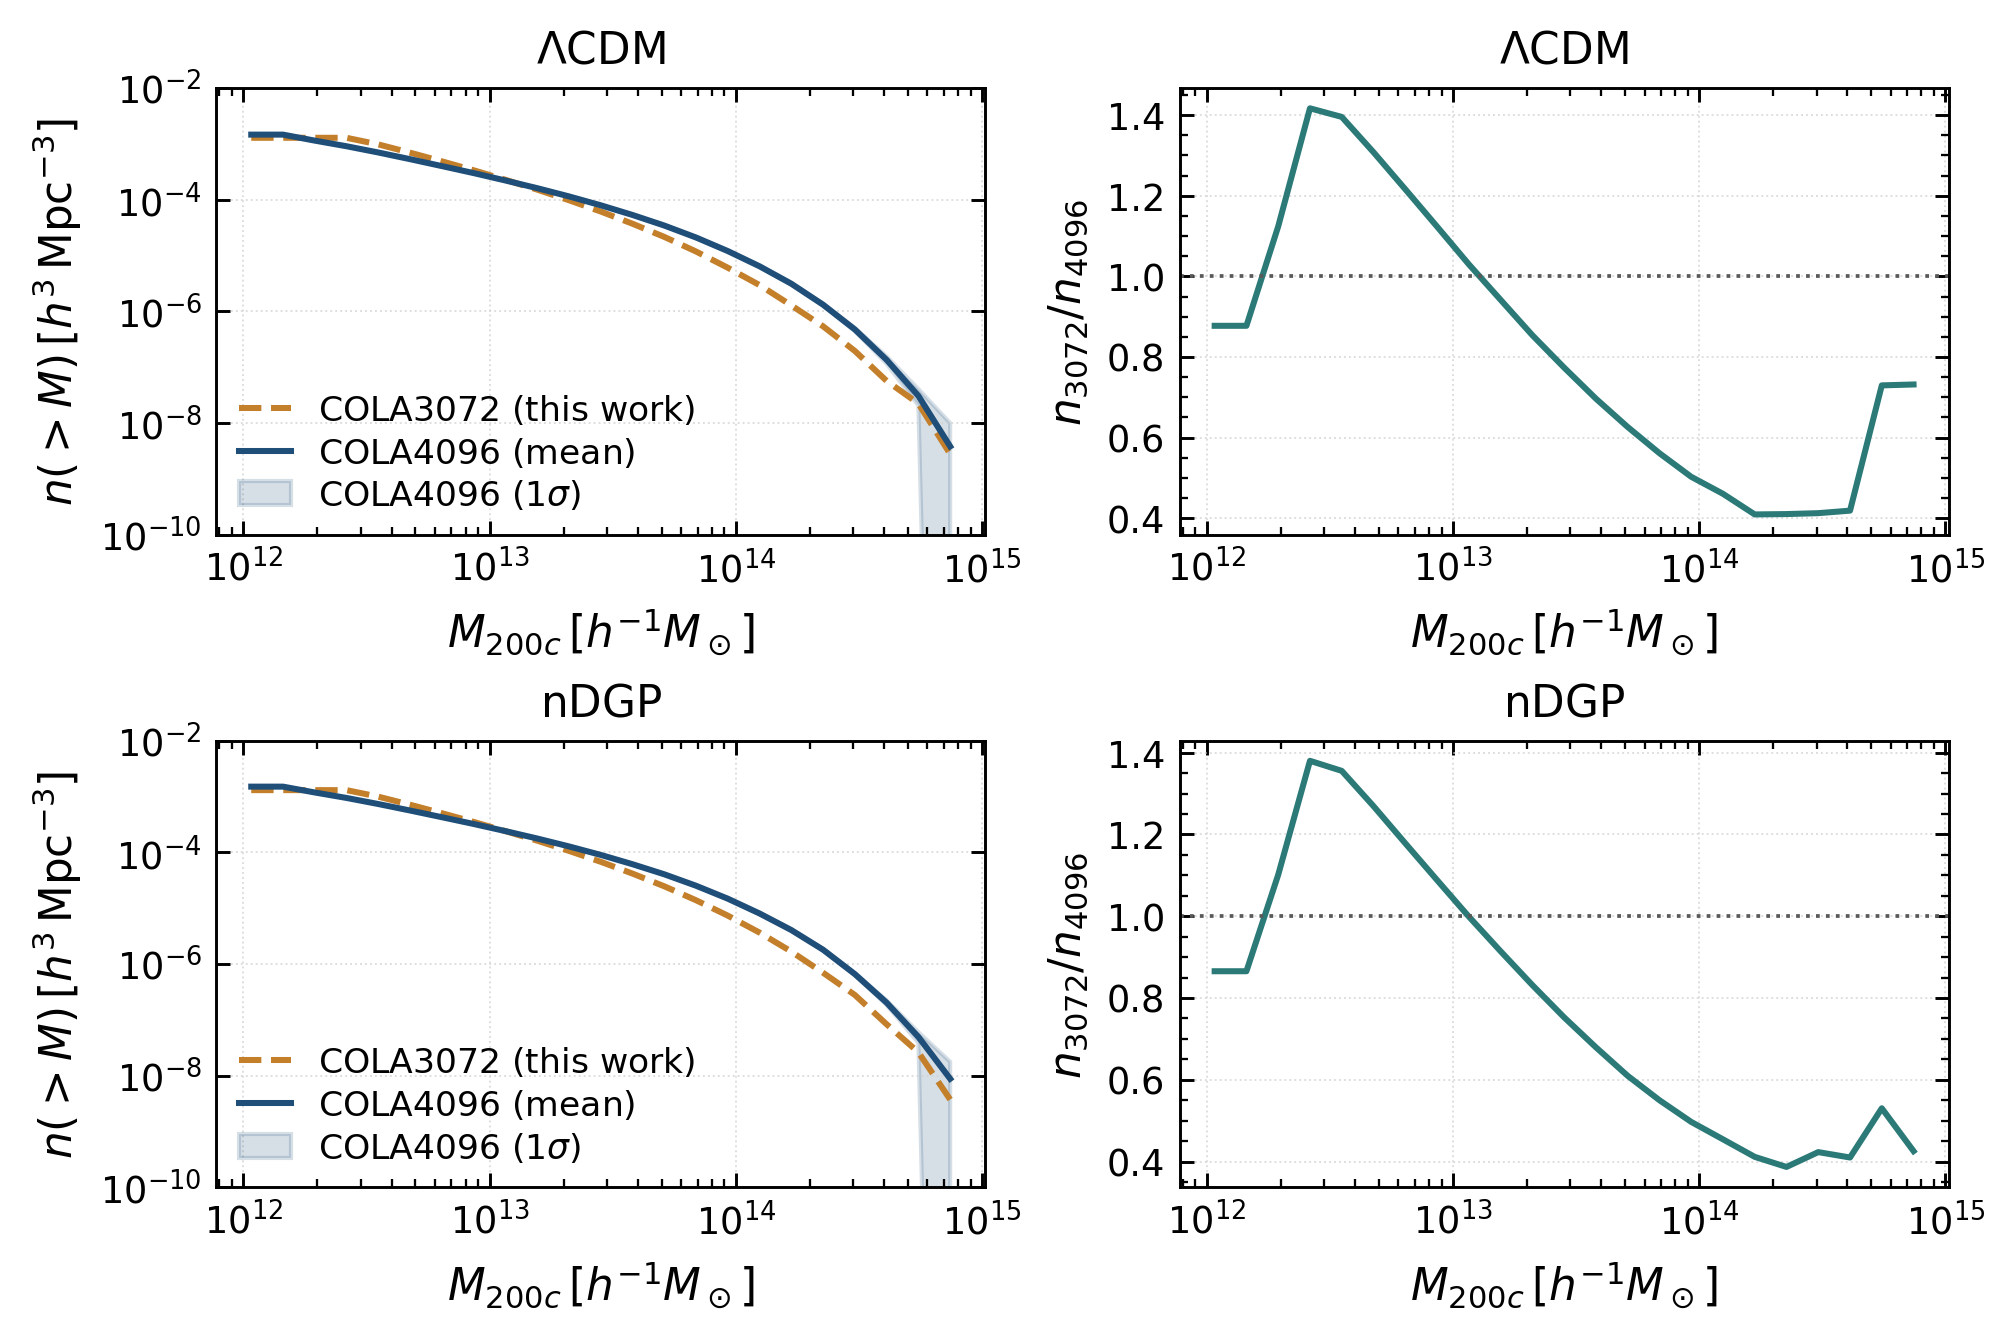

In [8]:
# Four-panel HMF comparison at z=1.650: LCDM (top row) vs nDGP (bottom row)
M_LCDM_Bart_plot = np.asarray(M_LCDM_Bart)
hmf_LCDM_Bart_plot = np.asarray(hmf_LCDM_Bart)
hmf_LCDM_Bart_std_plot = np.asarray(hmf_LCDM_Bart_std)
M_nDGP_Bart_plot = np.asarray(M_nDGP_Bart)
hmf_nDGP_Bart_plot = np.asarray(hmf_nDGP_Bart)
hmf_nDGP_Bart_std_plot = np.asarray(hmf_nDGP_Bart_std)
bart_label = r'$\mathrm{COLA4096\ (mean)}$'

M_LCDM_Me_plot = np.asarray(M_LCDM_Me)
hmf_LCDM_Me_plot = np.asarray(hmf_LCDM_Me)
M_nDGP_Me_plot = np.asarray(M_nDGP_Me)
hmf_nDGP_Me_plot = np.asarray(hmf_nDGP_Me)

hmf_LCDM_Me_on_Bart = np.interp(M_LCDM_Bart_plot, M_LCDM_Me_plot, hmf_LCDM_Me_plot)
hmf_nDGP_Me_on_Bart = np.interp(M_nDGP_Bart_plot, M_nDGP_Me_plot, hmf_nDGP_Me_plot)

hmf_LCDM_Bart_low = np.maximum(hmf_LCDM_Bart_plot - hmf_LCDM_Bart_std_plot, 1e-30)
hmf_LCDM_Bart_high = hmf_LCDM_Bart_plot + hmf_LCDM_Bart_std_plot
hmf_LCDM_COLA_over_Bart = np.divide(
    hmf_LCDM_Me_on_Bart,
    hmf_LCDM_Bart_plot,
    out=np.full_like(hmf_LCDM_Bart_plot, np.nan, dtype=float),
    where=hmf_LCDM_Bart_plot > 0,
)
hmf_LCDM_COLA_over_Bart_low = np.divide(
    hmf_LCDM_Me_on_Bart,
    hmf_LCDM_Bart_high,
    out=np.full_like(hmf_LCDM_Bart_plot, np.nan, dtype=float),
    where=hmf_LCDM_Bart_high > 0,
)
hmf_LCDM_COLA_over_Bart_high = np.divide(
    hmf_LCDM_Me_on_Bart,
    hmf_LCDM_Bart_low,
    out=np.full_like(hmf_LCDM_Bart_plot, np.nan, dtype=float),
    where=hmf_LCDM_Bart_low > 0,
)

hmf_nDGP_Bart_low = np.maximum(hmf_nDGP_Bart_plot - hmf_nDGP_Bart_std_plot, 1e-30)
hmf_nDGP_Bart_high = hmf_nDGP_Bart_plot + hmf_nDGP_Bart_std_plot
hmf_nDGP_COLA_over_Bart = np.divide(
    hmf_nDGP_Me_on_Bart,
    hmf_nDGP_Bart_plot,
    out=np.full_like(hmf_nDGP_Bart_plot, np.nan, dtype=float),
    where=hmf_nDGP_Bart_plot > 0,
)
hmf_nDGP_COLA_over_Bart_low = np.divide(
    hmf_nDGP_Me_on_Bart,
    hmf_nDGP_Bart_high,
    out=np.full_like(hmf_nDGP_Bart_plot, np.nan, dtype=float),
    where=hmf_nDGP_Bart_high > 0,
)
hmf_nDGP_COLA_over_Bart_high = np.divide(
    hmf_nDGP_Me_on_Bart,
    hmf_nDGP_Bart_low,
    out=np.full_like(hmf_nDGP_Bart_plot, np.nan, dtype=float),
    where=hmf_nDGP_Bart_low > 0,
)

fig_size = (6.6, 4.35)
label_size = 10.5
tick_size = 8.8
legend_size = 8.3
line_width = 1.45
std_alpha = 0.18
cola_color = '#c47f2b'
bart_color = '#1f4e79'
ratio_color = '#2b7a78'
band_color = bart_color
ref_color = '0.35'

fig, axes = plt.subplots(2, 2, figsize=fig_size, dpi=300, constrained_layout=True)
ax_tl, ax_tr = axes[0]
ax_bl, ax_br = axes[1]

# Top row: LCDM
mask_me_lcdm = (hmf_LCDM_Me_plot > 0) & (M_LCDM_Me_plot >= 1e12)
mask_bart_lcdm = (hmf_LCDM_Bart_plot > 0) & (M_LCDM_Bart_plot >= 1e12)
ax_tl.loglog(M_LCDM_Me_plot[mask_me_lcdm], hmf_LCDM_Me_plot[mask_me_lcdm], lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA3072\ (this\ work)}$')
ax_tl.loglog(M_LCDM_Bart_plot[mask_bart_lcdm], hmf_LCDM_Bart_plot[mask_bart_lcdm], lw=line_width, color=bart_color, label=bart_label)
ax_tl.fill_between(
    M_LCDM_Bart_plot[mask_bart_lcdm],
    hmf_LCDM_Bart_low[mask_bart_lcdm],
    hmf_LCDM_Bart_high[mask_bart_lcdm],
    color=band_color,
    alpha=std_alpha,
    label=r'$\mathrm{COLA4096}\ (1\sigma)$',
)
ax_tl.set_xlabel(r'$M_{200c}\,[h^{-1}M_\odot]$', fontsize=label_size)
ax_tl.set_ylabel(r'$n(>M)\,[h^3\,\mathrm{Mpc}^{-3}]$', fontsize=label_size)
ax_tl.set_ylim(1e-10, 1e-2)
ax_tl.set_title(r'$\Lambda\mathrm{CDM}$', fontsize=label_size)
ax_tl.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)

mask_lcdm_ratio = np.isfinite(hmf_LCDM_COLA_over_Bart) & (hmf_LCDM_Bart_plot > 0) & (M_LCDM_Bart_plot >= 1e12)
# The Bart 1-sigma band is not shown here: at the high-mass tail some bins have
# std > mean, so mean-std hits the 1e-30 floor and the ratio's upper bound blows up.
ax_tr.semilogx(M_LCDM_Bart_plot[mask_lcdm_ratio], hmf_LCDM_COLA_over_Bart[mask_lcdm_ratio], lw=line_width, color=ratio_color)
ax_tr.axhline(1.0, color=ref_color, lw=0.9, ls=':')
ax_tr.set_xlabel(r'$M_{200c}\,[h^{-1}M_\odot]$', fontsize=label_size)
ax_tr.set_ylabel(r'$n_{\mathrm{3072}} / n_{\mathrm{4096}}$', fontsize=label_size)
ax_tr.set_title(r'$\Lambda\mathrm{CDM}$', fontsize=label_size)

# Bottom row: nDGP
mask_me_ndgp = (hmf_nDGP_Me_plot > 0) & (M_nDGP_Me_plot >= 1e12)
mask_bart_ndgp = (hmf_nDGP_Bart_plot > 0) & (M_nDGP_Bart_plot >= 1e12)
ax_bl.loglog(M_nDGP_Me_plot[mask_me_ndgp], hmf_nDGP_Me_plot[mask_me_ndgp], lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA3072\ (this\ work)}$')
ax_bl.loglog(M_nDGP_Bart_plot[mask_bart_ndgp], hmf_nDGP_Bart_plot[mask_bart_ndgp], lw=line_width, color=bart_color, label=bart_label)
ax_bl.fill_between(
    M_nDGP_Bart_plot[mask_bart_ndgp],
    hmf_nDGP_Bart_low[mask_bart_ndgp],
    hmf_nDGP_Bart_high[mask_bart_ndgp],
    color=band_color,
    alpha=std_alpha,
    label=r'$\mathrm{COLA4096}\ (1\sigma)$',
)
ax_bl.set_xlabel(r'$M_{200c}\,[h^{-1}M_\odot]$', fontsize=label_size)
ax_bl.set_ylabel(r'$n(>M)\,[h^3\,\mathrm{Mpc}^{-3}]$', fontsize=label_size)
ax_bl.set_ylim(1e-10, 1e-2)
ax_bl.set_title(r'$\mathrm{nDGP}$', fontsize=label_size)
ax_bl.legend(fontsize=legend_size, frameon=False, handlelength=1.5, borderaxespad=0.25, labelspacing=0.25)

mask_ndgp_ratio = np.isfinite(hmf_nDGP_COLA_over_Bart) & (hmf_nDGP_Bart_plot > 0) & (M_nDGP_Bart_plot >= 1e12)
# Same reasoning as the LCDM ratio panel above: band omitted to avoid the tail blow-up.
ax_br.semilogx(M_nDGP_Bart_plot[mask_ndgp_ratio], hmf_nDGP_COLA_over_Bart[mask_ndgp_ratio], lw=line_width, color=ratio_color)
ax_br.axhline(1.0, color=ref_color, lw=0.9, ls=':')
ax_br.set_xlabel(r'$M_{200c}\,[h^{-1}M_\odot]$', fontsize=label_size)
ax_br.set_ylabel(r'$n_{\mathrm{3072}} / n_{\mathrm{4096}}$', fontsize=label_size)
ax_br.set_title(r'$\mathrm{nDGP}$', fontsize=label_size)

for ax in (ax_tl, ax_tr, ax_bl, ax_br):
    ax.minorticks_on()
    ax.grid(True, which='major', ls=':', color='0.82', alpha=0.75, lw=0.45)
    ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, labelsize=tick_size, length=3.4, width=0.7)
    ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, labelsize=tick_size - 0.8, length=2.0, width=0.55)
    for spine in ax.spines.values():
        spine.set_linewidth(0.7)

plt.show()

# Plot 6b

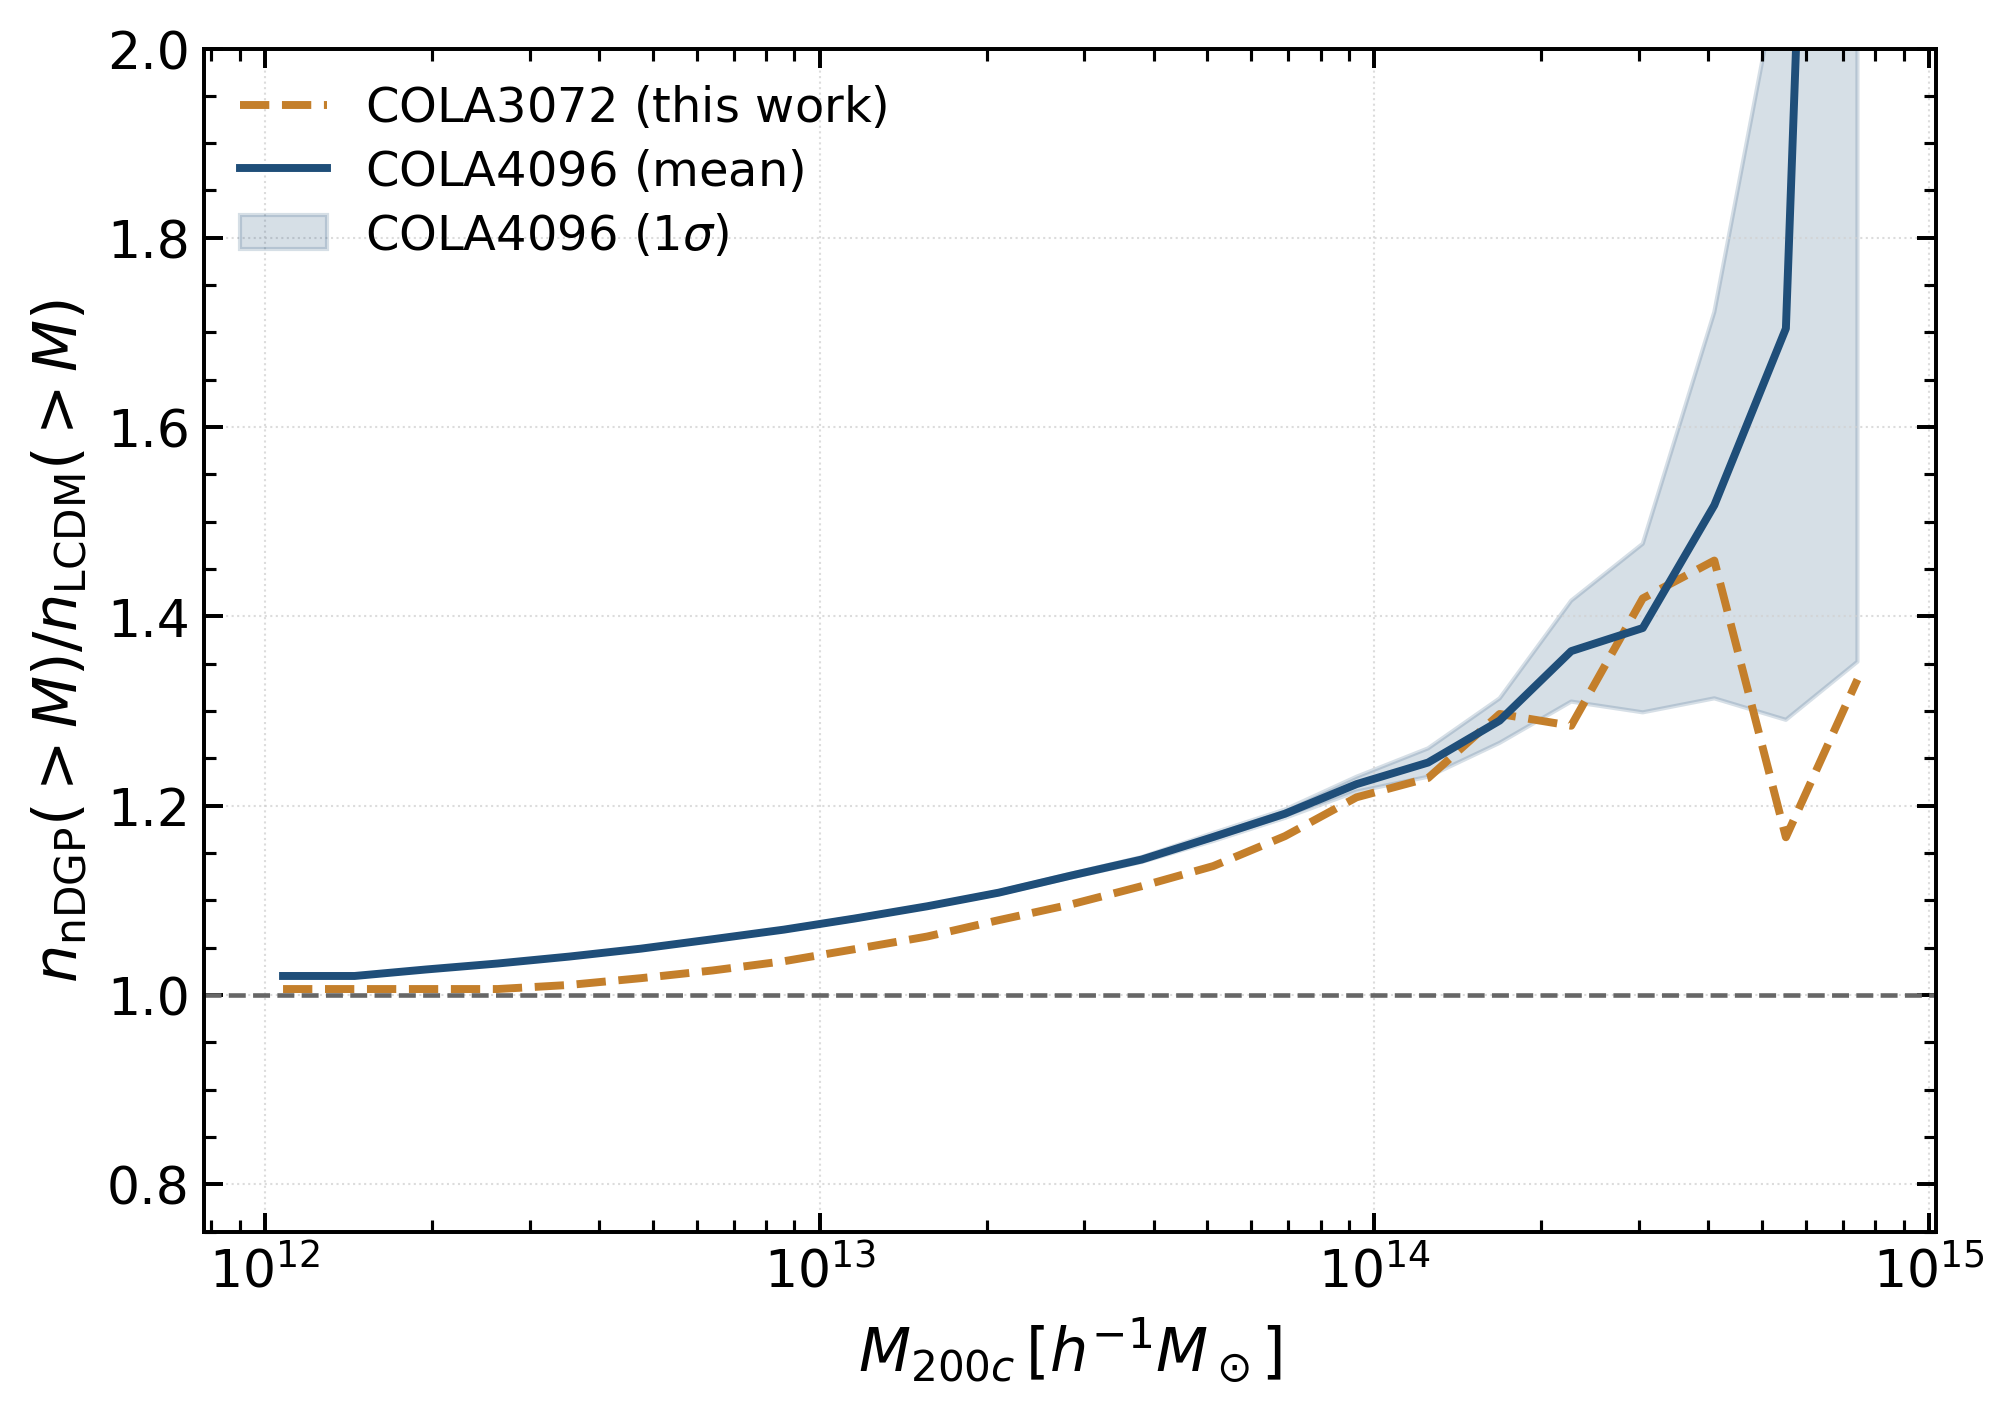

In [15]:
# nDGP / LCDM HMF ratio at z=1.650
M_LCDM_Bart_plot = np.asarray(M_LCDM_Bart)
hmf_LCDM_Bart_plot = np.asarray(hmf_LCDM_Bart)
M_LCDM_Me_plot = np.asarray(M_LCDM_Me)
hmf_LCDM_Me_plot = np.asarray(hmf_LCDM_Me)
M_nDGP_Me_plot = np.asarray(M_nDGP_Me)
hmf_nDGP_Me_plot = np.asarray(hmf_nDGP_Me)
bart_label = r'$\mathrm{COLA4096\ (mean)}$'

hmf_nDGP_Me_on_LCDM = np.interp(M_LCDM_Me_plot, M_nDGP_Me_plot, hmf_nDGP_Me_plot)
hmf_nDGP_over_LCDM_Me = np.divide(
    hmf_nDGP_Me_on_LCDM,
    hmf_LCDM_Me_plot,
    out=np.full_like(hmf_LCDM_Me_plot, np.nan, dtype=float),
    where=hmf_LCDM_Me_plot > 0,
)
mask_me_ratio = np.isfinite(hmf_nDGP_over_LCDM_Me) & (M_LCDM_Me_plot >= 1e12)
mask_bart_ratio = (hmf_LCDM_Bart_plot > 0) & np.isfinite(hmf_nDGP_over_LCDM_Bart) & (M_LCDM_Bart_plot >= 1e12)

# This is a standalone, one-column figure (unlike the four-panel plot above), so it will be
# shrunk more to fit a document column -- sizes here are scaled up accordingly to stay readable.
fig_size = (6.6, 4.6)
label_size = 14.5
tick_size = 12.5
legend_size = 11.5
line_width = 1.9
std_alpha = 0.18
cola_color = '#c47f2b'
bart_color = '#1f4e79'
band_color = bart_color

fig, ax = plt.subplots(figsize=fig_size, dpi=300, constrained_layout=True)

ax.semilogx(M_LCDM_Me_plot[mask_me_ratio], hmf_nDGP_over_LCDM_Me[mask_me_ratio], lw=line_width, color=cola_color, ls='--', label=r'$\mathrm{COLA3072\ (this\ work)}$')
ax.semilogx(M_LCDM_Bart_plot[mask_bart_ratio], hmf_nDGP_over_LCDM_Bart[mask_bart_ratio], lw=line_width, color=bart_color, label=bart_label)
ax.fill_between(
    M_LCDM_Bart_plot[mask_bart_ratio],
    (hmf_nDGP_over_LCDM_Bart - hmf_nDGP_over_LCDM_Bart_std)[mask_bart_ratio],
    (hmf_nDGP_over_LCDM_Bart + hmf_nDGP_over_LCDM_Bart_std)[mask_bart_ratio],
    color=band_color,
    alpha=std_alpha,
    label=r'$\mathrm{COLA4096}\ (1\sigma)$',
)
ax.set_xlabel(r'$M_{200c}\,[h^{-1}M_\odot]$', fontsize=label_size)
ax.set_ylabel(r'$n_{\mathrm{nDGP}}(>M) / n_{\mathrm{LCDM}}(>M)$', fontsize=label_size)
ax.set_ylim(0.75,2)
ax.legend(fontsize=legend_size, frameon=False, handlelength=1.8, borderaxespad=0.35, labelspacing=0.35)
ax.axhline(1.0, color='0.4', lw=1.1, ls='--')

ax.minorticks_on()
ax.grid(True, which='major', ls=':', color='0.82', alpha=0.75, lw=0.5)
ax.tick_params(axis='both', which='major', direction='in', top=True, right=True, labelsize=tick_size, length=4.6, width=0.95)
ax.tick_params(axis='both', which='minor', direction='in', top=True, right=True, labelsize=tick_size - 1.2, length=2.8, width=0.75)
for spine in ax.spines.values():
    spine.set_linewidth(0.95)

plt.show()